In [1]:
%%bash
[[ ! -e /content/sample_data ]] && exit  ## run this cell only in colab
 
pip install optax -qqq
pip install networkx==2.5 -qqq
pip install netgraph
git clone https://github.com/ramithuh/differentiable-trees --quiet

In [46]:
%load_ext autoreload
%autoreload 2

import os
import sys

if(os.path.exists('/content/sample_data')):
  sys.path.append('differentiable-trees/')

import jax.numpy as jnp
import jax.nn as nn
import jax
import optax
import functools

import pydot
import numpy as np
from helpers import *

from matplotlib import rc
rc('animation', html='jshtml')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [47]:
key = jax.random.PRNGKey(42)

## Sequences

In [48]:
# sequences (fixed)
n_leaves    = 4
n_ancestors = n_leaves - 1

seq_length = 4

n_all = n_leaves + n_ancestors


blank = jnp.array([0,0,0,0])

In [49]:
# similarity matrix (fixed)
sm = jnp.array([[0,1],
               [1,0]])

In [50]:
seqs = jax.random.randint(key, shape = (n_all, seq_length), minval = 0, maxval = 2).astype(jnp.float32)

In [51]:
base_tree = jnp.zeros((n_all, n_all))

In [52]:
seqs

DeviceArray([[1., 0., 0., 0.],
             [1., 0., 1., 0.],
             [1., 1., 1., 1.],
             [0., 0., 0., 0.],
             [0., 1., 0., 1.],
             [0., 0., 0., 1.],
             [1., 0., 0., 1.]], dtype=float32)

## Tree Topology (also parameterized)

### initialize parameters

In [53]:
optimizer = optax.adam(1)

params = {'t': jax.random.normal(key, (n_all - 1,n_ancestors))}


for i in range(0, n_ancestors):
    params[chr(97+i + n_leaves)] = jax.random.normal(key, (seq_length,))
    

opt_state = optimizer.init(params)

In [54]:
params.keys()

dict_keys(['t', 'e', 'f', 'g'])

In [55]:
# t_q = jnp.argmax(t_softmax,axis = 1).T

In [56]:
base_tree.shape

(7, 7)

In [63]:
import jaxlib

In [64]:
jaxlib.__version__

'0.3.22'

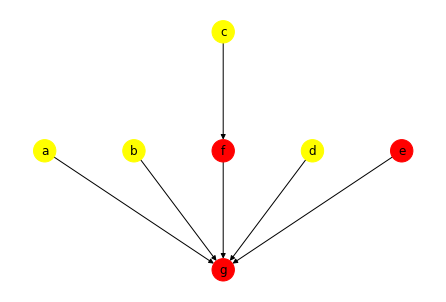

In [60]:
k = show_graph_with_labels(discretize_tree_topology(update_tree(params, base_tree), n_all),n_leaves, True)

In [62]:
type(k)

matplotlib.figure.Figure

### Function to compute total distance

In [14]:
def compute_cost(sequences, tree, verbose = False, average = True):
    if(verbose==True):
        show_graph_with_labels(discretize_tree_topology(tree, n_all),n_leaves)
        
    selection = jnp.matmul(tree,sequences)
    # print(selection)
    
#     #method 1: (downside needs integers as we are indexing)
#     selection = selection.astype(int)
#     ans = sm[selection,sequences].sum()
    
    #method 2:
    if(average):
        ans = abs(selection - sequences).sum() ## works currently as sm is the basic config. need to think about extending
    else:
        ans = jnp.sum(abs(selection - sequences), axis = 1)
    
    return ans

In [15]:
update_tree(params, base_tree)

DeviceArray([[0.        , 0.        , 0.        , 0.        , 0.30321804,
              0.16727467, 0.5295073 ],
             [0.        , 0.        , 0.        , 0.        , 0.3965519 ,
              0.12775946, 0.4756886 ],
             [0.        , 0.        , 0.        , 0.        , 0.12712821,
              0.8479232 , 0.02494855],
             [0.        , 0.        , 0.        , 0.        , 0.31710118,
              0.2897718 , 0.39312702],
             [0.        , 0.        , 0.        , 0.        , 0.20008957,
              0.17309996, 0.62681043],
             [0.        , 0.        , 0.        , 0.        , 0.14293277,
              0.3836567 , 0.47341058],
             [0.        , 0.        , 0.        , 0.        , 0.        ,
              0.        , 1.        ]], dtype=float32)

DeviceArray(11.29579, dtype=float32)

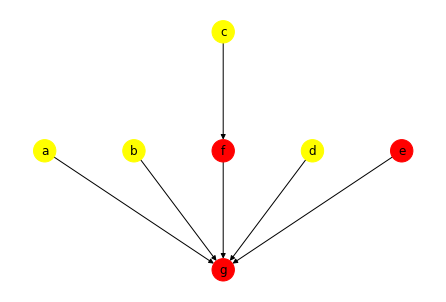

In [16]:
compute_cost(seqs,update_tree(params, base_tree),1)

In [17]:
params

{'t': DeviceArray([[-0.63462436, -1.2294393 , -0.07712954],
              [-0.22857422, -1.3612318 , -0.04661765],
              [-0.14380704,  1.7537868 , -1.7721876 ],
              [ 0.18559739,  0.09547025,  0.40050933],
              [ 0.9773695 ,  0.83247375,  2.1192486 ],
              [-0.67893344,  0.3084403 ,  0.51865524]], dtype=float32),
 'e': DeviceArray([ 0.18693547,  1.0653336 , -1.5593132 , -1.5352962 ], dtype=float32),
 'f': DeviceArray([ 0.18693547,  1.0653336 , -1.5593132 , -1.5352962 ], dtype=float32),
 'g': DeviceArray([ 0.18693547,  1.0653336 , -1.5593132 , -1.5352962 ], dtype=float32)}

In [18]:
n_all

7

In [19]:
# tree_force_loss = 0 

# t_new = discretize_tree_topology(update_tree(params, base_tree), n_leaves + n_ancestors)

# for k in range(n_all - 1, n_all - 1 - n_ancestors, -1):
#     tree_force_loss += (abs(t_new[:-1,k].sum()-2))**2

# print(tree_force_loss)

In [20]:
def regularize_graph(t_, s, verbose = False):
    
    tree_force_loss = jnp.sum(jnp.power(s*jnp.abs(jnp.sum(t_[:-1, n_all - n_ancestors: n_all], axis = 0) - 2),2))
    
    #tree_force_loss = (s*abs(t_[:-1,-2].sum()-2))**2 + (s*abs(t_[:-1,-1].sum()-2))**2
    
    loop_loss = jnp.multiply(jnp.identity(n_all-1), t_[:-1,:-1]).sum()*100  ## penalize self connections
    
    
    if(verbose):
        print("bifurcating tree_forcing_loss = ", tree_force_loss)
        print("self loop_loss = ", loop_loss)
    
    return tree_force_loss + loop_loss

In [21]:
def compute_loss(params, seqs, base_tree, verbose = False):
    seqs_ = combine_to_seq(params, seqs, n_leaves, n_all)
    t_    = update_tree(params, base_tree)

    loss  = compute_cost(seqs_,t_) + regularize_graph(t_,10, verbose)
    
    return loss

In [22]:
compute_loss(params, seqs, base_tree)

DeviceArray(119.85344, dtype=float32)

In [23]:
trees = []

for _ in range(1500):
    grads = jax.grad(compute_loss)(params, seqs, base_tree)
    
    
    t_= update_tree(params, base_tree)
    t__ = discretize_tree_topology(t_,n_all)
    t__ = t__.at[-1,-1].set(0)
    
    trees.append(t__)
    
    if(_%100==0):
        # temp  = combine_to_seq(params, seqs)
        
        print("{:.5f}".format(compute_loss(params, seqs, base_tree)),end = " seq = {}\n")
        #print(t_[:,-2],",",t_[:,-1],end="}\n")
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)


119.85344 seq = {}
5.01238 seq = {}
5.00703 seq = {}
5.00524 seq = {}
5.00421 seq = {}
5.00348 seq = {}
5.00295 seq = {}
5.00254 seq = {}
5.00223 seq = {}
5.00197 seq = {}
5.00176 seq = {}
5.00158 seq = {}
5.00143 seq = {}
5.00130 seq = {}
5.00118 seq = {}


In [24]:
adjacency_matrix2 = jnp.array(trees)

In [25]:
# anim = animate_tree(adjacency_matrix2, n_leaves, n_ancestors, total_frames = 500 )

In [26]:
#anim.save(f"nodes_{n_all}.mp4")

In [27]:
t_new = discretize_tree_topology(update_tree(params, base_tree), n_leaves + n_ancestors)

In [28]:
discretized = jnp.round(combine_to_seq(params, seqs, n_leaves, n_all))

In [29]:
compute_loss(params, seqs, base_tree, 1)

bifurcating tree_forcing_loss =  2.4552539e-05
self loop_loss =  0.0009930386


DeviceArray(5.0010824, dtype=float32)

In [30]:
t_new

DeviceArray([[0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.]], dtype=float32)

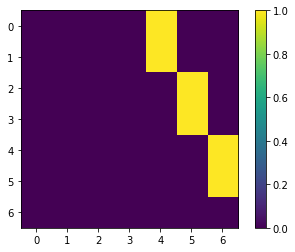

In [31]:
plt.imshow(adjacency_matrix2[300])
plt.colorbar()

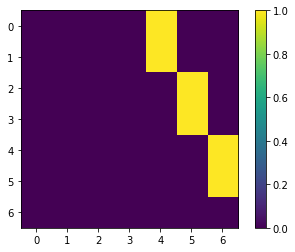

In [32]:
plt.imshow(adjacency_matrix2[-1])
plt.colorbar()


## Retrieving the new sequences array

In [33]:
t_new = discretize_tree_topology(update_tree(params, base_tree), n_leaves + n_ancestors)

In [34]:
combine_to_seq(params, seqs, n_leaves, n_all)

DeviceArray([[1.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
             [1.0000000e+00, 0.0000000e+00, 1.0000000e+00, 0.0000000e+00],
             [1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00],
             [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00],
             [9.9999547e-01, 1.2284085e-05, 7.2918003e-05, 1.0370464e-06],
             [9.9999225e-01, 2.3521532e-05, 7.2895898e-05, 1.5299514e-05],
             [9.9999225e-01, 2.3494673e-05, 7.2743125e-05, 1.5278169e-05]],            dtype=float32)

In [35]:
discretized = jnp.round(combine_to_seq(params, seqs, n_leaves, n_all))

In [36]:
discretized

DeviceArray([[1., 0., 0., 0.],
             [1., 0., 1., 0.],
             [1., 1., 1., 1.],
             [0., 0., 0., 0.],
             [1., 0., 0., 0.],
             [1., 0., 0., 0.],
             [1., 0., 0., 0.]], dtype=float32)

In [37]:
seqs

DeviceArray([[1., 0., 0., 0.],
             [1., 0., 1., 0.],
             [1., 1., 1., 1.],
             [0., 0., 0., 0.],
             [0., 1., 0., 1.],
             [0., 0., 0., 1.],
             [1., 0., 0., 1.]], dtype=float32)

In [38]:
params

{'e': DeviceArray([ 12.301158, -11.307194,  -9.526102, -13.779133], dtype=float32),
 'f': DeviceArray([ 11.761428, -10.657571,  -9.526405, -11.087674], dtype=float32),
 'g': DeviceArray([ 11.767553, -10.658713,  -9.528503, -11.08907 ], dtype=float32),
 't': DeviceArray([[ 4.500535 , -1.3144338, -3.8801134],
              [ 4.005107 , -2.4355052, -2.357034 ],
              [-2.8556983,  5.252936 , -7.726928 ],
              [-0.6602106,  4.448673 , -3.4021206],
              [-3.8651736,  1.4118586,  7.6746607],
              [-4.0878186, -8.730623 ,  6.624332 ]], dtype=float32)}

### New cost

In [39]:
t_new

DeviceArray([[0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.]], dtype=float32)

DeviceArray(5., dtype=float32)

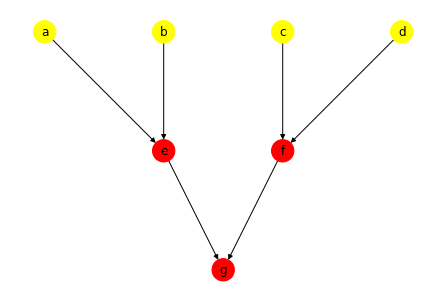

In [40]:
compute_cost(discretized, t_new, 1)

In [41]:
t_new

DeviceArray([[0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.]], dtype=float32)

### Old cost

In [42]:
compute_cost(seqs, base_tree) ##when d & e were all zeros

DeviceArray(12., dtype=float32)

### test arbitrary sequence for d & e

In [43]:
test = jnp.array([[0, 0., 0., 0.],
                 [1., 0., 0., 1.],
                 [0., 1., 1., 0.],
                 [0., 0., 0., 0.],
                 [0., 0., 0., 0.]])

In [44]:
# compute_cost(test, t_new)